In [ ]:
!pip install numpy matplotlib scikit-learn tensorflow

Dataset shape: (1000, 2)
Target shape: (1000,)


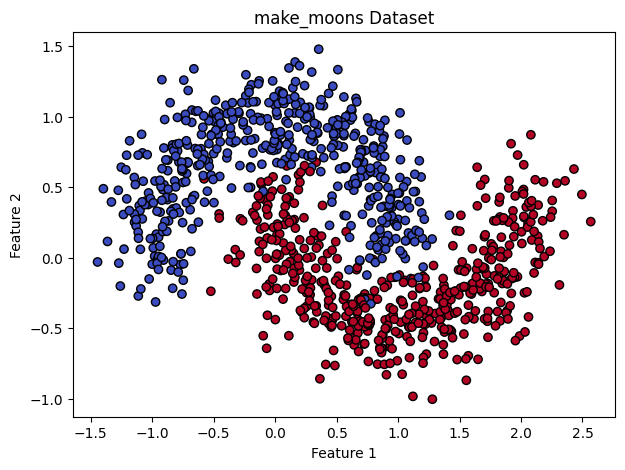

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            48 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 465 (1.82 KB)

 Trainable params: 465 (1.82 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.6562 - loss: 0.6469 - val_accuracy: 0.7250 - val_loss: 0.6022
Epoch 2/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7266 - loss: 0.5872 - val_accuracy: 0.8375 - val_loss: 0.5346
Epoch 3/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8000 - loss: 0.5335 - val_accuracy: 0.8687 - val_loss: 0.4783
Epoch 4/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8422 - loss: 0.4893 - val_accuracy: 0.9062 - val_loss: 0.4313
Epoch 5/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8516 - loss: 0.4513 - val_accuracy: 0.9125 - val_loss: 0.3908
Epoch 6/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8625 - loss: 0.4166 - val_accuracy: 0.9125 - val_loss: 0.3496
Epoch 7/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8656 - loss: 0.3844 - val_accuracy: 0.9062 - val_loss: 0.3114
Epoch 8/150
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8703 - loss: 0.3548 - val_accuracy: 0.9125 - 

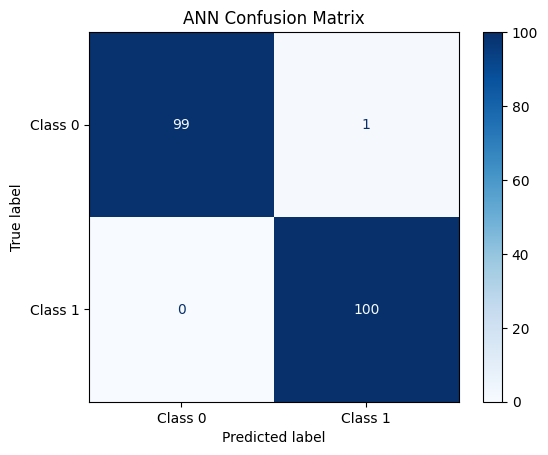

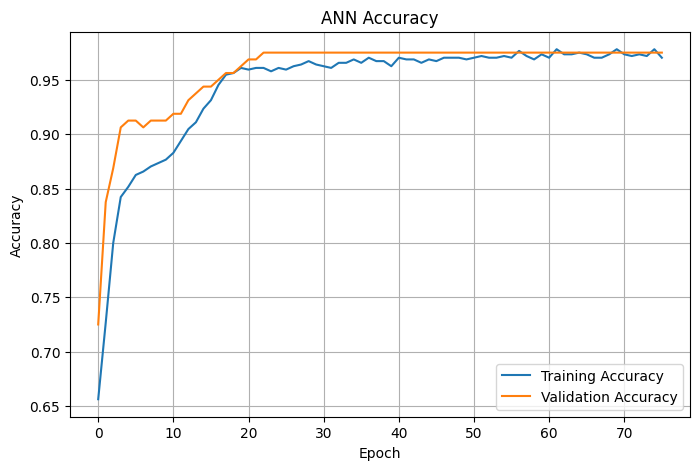

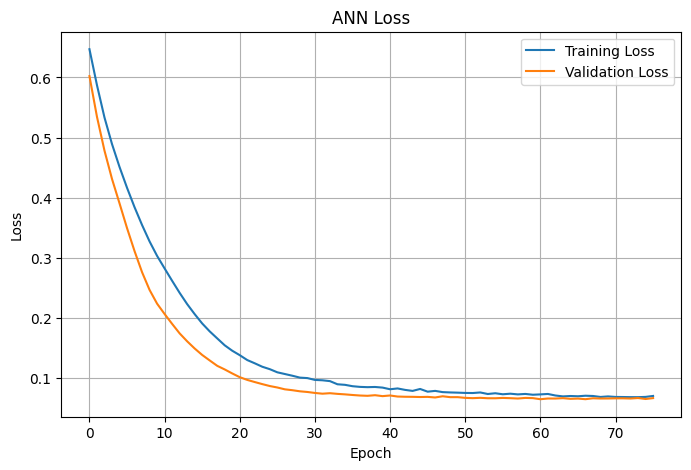

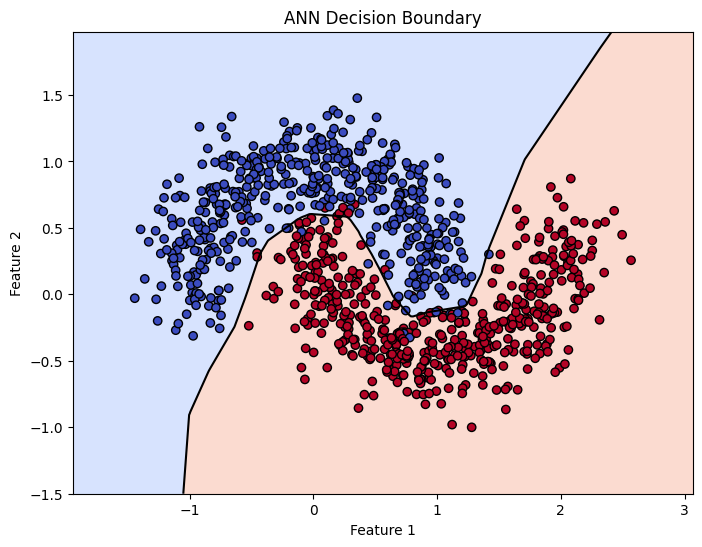


New Sample: [[0.5 0.2]]
Probability of Class 1: 0.6287
Predicted Class: 1

Model saved as ann_make_moons.keras


In [ ]:

# PROJECT 1: ANN FOR BINARY CLASSIFICATION
# Dataset: make_moons from Scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

# 1. Generate the dataset
X, y = make_moons(
    n_samples=1000,
    noise=0.20,
    random_state=42
)

print("Dataset shape:", X.shape)
print("Target shape:", y.shape)

# 2. Visualize the original dataset
plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.title("make_moons Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 3. Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# 4. Standardize the input features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 5. Build the ANN model
model = Sequential([
    Input(shape=(2,)),
    Dense(16, activation="relu"),
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),
    Dense(1, activation="sigmoid")
])

# 6. Compile the model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Display the architecture
model.summary()

# 7. Train the ANN
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

# 8. Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("\nTest Loss:", round(loss, 4))
print("Test Accuracy:", round(accuracy * 100, 2), "%")

# 9. Predict test labels
probabilities = model.predict(X_test, verbose=0).ravel()
y_pred = (probabilities >= 0.5).astype(int)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Class 0", "Class 1"]
).plot(cmap="Blues")

plt.title("ANN Confusion Matrix")
plt.show()

# 11. Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ANN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# 12. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ANN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

# 13. Visualize the learned decision boundary
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid)

Z = model.predict(grid_scaled, verbose=0).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, levels=[0, 0.5, 1], cmap="coolwarm", alpha=0.35)
plt.contour(xx, yy, Z, levels=[0.5], colors="black")
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", edgecolors="k")
plt.title("ANN Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# 14. Test a new sample
new_sample = np.array([[0.5, 0.2]])
new_sample_scaled = scaler.transform(new_sample)

prediction = model.predict(new_sample_scaled, verbose=0)[0][0]
predicted_class = int(prediction >= 0.5)

print("\nNew Sample:", new_sample)
print("Probability of Class 1:", round(float(prediction), 4))
print("Predicted Class:", predicted_class)

# 15. Save the trained model
model.save("ann_make_moons.keras")
print("\nModel saved as ann_make_moons.keras")
